# 01 · Data Preprocessing

**Research question:** Are Vision Transformers more robust detectors of AI-generated images than CNNs?

This notebook prepares every dataset used in the project:

1. Download CIFAKE (Bird & Lotfi, 2024) and three extended datasets from Jiang (2024)
2. Identify every image, its label (REAL / FAKE) and its CIFAR-10 class
3. Build class-balanced training, validation and test splits
4. Decode the images, check for leakage between splits and save the results
5. Exploratory analysis: sample images and frequency spectra

**Outputs** (`outputs/data/`): one `.npz` file per split, plus `manifest.csv`, which records the source file of every image.

In [2]:
# Environment setup: libraries, persistent storage and global settings
%pip install -q -U kagglehub kaggle

import os
import re
import io
import json
import hashlib
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from PIL import Image, ImageFilter
import torch
from tqdm.auto import tqdm
from google.colab import drive, userdata

# Colab's local disk is wiped when the session ends, so all outputs live in Google Drive
drive.mount("/content/drive")
PROJECT_DIR = Path("/content/drive/MyDrive/MAAI901_AIImageDetector")

DATA_DIR = PROJECT_DIR / "outputs" / "data"
MODEL_DIR = PROJECT_DIR / "outputs" / "models"
RESULTS_DIR = PROJECT_DIR / "outputs" / "results"
FIG_DIR = PROJECT_DIR / "outputs" / "figures"
for folder in (DATA_DIR, MODEL_DIR, RESULTS_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 42
REAL, FAKE = 0, 1                      # FAKE is the positive class (the detection target)
LABEL_NAMES = {REAL: "REAL", FAKE: "FAKE"}
TRAIN_SETUPS = ("trainSD14", "trainSD21")
TEST_SETS = {                          # split name -> generator behind the fake images
    "test_sd14": "SD 1.4",
    "test_sd21": "SD 2.1",
    "test_sd30": "SD 3.0",
    "test_sd21blur": "SD 2.1 blurred",
}

CIFAR10_CLASSES = ("airplane", "automobile", "bird", "cat", "deer",
                   "dog", "frog", "horse", "ship", "truck")

# Images per label in each split (real and fake are always balanced)
N_TRAIN, N_VAL, N_TEST = 10_000, 2_000, 10_000
IMG_SIZE = 32

# The Kaggle API token is read from Colab secrets, so it never appears in the notebook
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
print("Project folder:", PROJECT_DIR)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/MAAI901_AIImageDetector


## 1 · Data acquisition

| Key | Kaggle dataset | Fake images generated by |
|---|---|---|
| `cifake` | CIFAKE: Real and AI-Generated Synthetic Images | Stable Diffusion 1.4 |
| `sd21` | SD 2.1 CIFAKE 512-32JPG | Stable Diffusion 2.1 |
| `sd30` | Stable Diffusion 3.0 CIFAKE, 32x32 JPG (1024) | Stable Diffusion 3.0 |
| `sd21blur` | Gaussian Blurred SD2.1 Images | SD 2.1 + Gaussian blur |

Jiang's datasets are located through the Kaggle API by their exact titles, so the notebook doesn't depend on hand-copied links.

In [3]:
import kagglehub
import kaggle  # authenticates on import using KAGGLE_API_TOKEN

CIFAKE_SLUG = "birdy654/cifake-real-and-ai-generated-synthetic-images"
JIANG_OWNER = "justinjiangnext"
JIANG_TITLES = {
    "sd21": "SD 2.1 CIFAKE 512-32JPG",
    "sd30": "Stable Diffusion 3.0 CIFAKE, 32x32 JPG (1024)",
    "sd21blur": "Gaussian Blurred SD2.1 Images",
}


def normalise_title(title):
    """Lower-case, map the multiplication sign to 'x' and keep only letters and digits."""
    return re.sub(r"[^a-z0-9]", "", title.lower().replace("\u00d7", "x"))


def resolve_slugs(owner, titles):
    """Find 'owner/dataset' identifiers by matching dataset titles on the owner's profile."""
    available = {}
    for page in range(1, 10):
        batch = kaggle.api.dataset_list(user=owner, page=page) or []
        if not batch:
            break
        available.update({normalise_title(d.title): d.ref for d in batch})
    missing = [t for t in titles.values() if normalise_title(t) not in available]
    if missing:
        raise RuntimeError(f"Datasets not found for '{owner}': {missing}")
    return {key: available[normalise_title(t)] for key, t in titles.items()}


slugs = {"cifake": CIFAKE_SLUG, **resolve_slugs(JIANG_OWNER, JIANG_TITLES)}
roots = {key: Path(kagglehub.dataset_download(slug)) for key, slug in slugs.items()}
pd.DataFrame({"kaggle_id": slugs, "local_path": {k: str(v) for k, v in roots.items()}})

Using Colab cache for faster access to the 'cifake-real-and-ai-generated-synthetic-images' dataset.


100%|██████████| 55.7M/55.7M [00:01<00:00, 43.1MB/s]

Extracting files...


100%|██████████| 53.8M/53.8M [00:00<00:00, 78.9MB/s]

Extracting files...


100%|██████████| 44.0M/44.0M [00:00<00:00, 82.0MB/s]

Extracting files...


,kaggle_id,local_path
cifake,birdy654/cifake-real-and-ai-generated-syntheti...,/kaggle/input/cifake-real-and-ai-generated-syn...
sd21,justinjiangnext/d21cifake-512pxjpg,/root/.cache/kagglehub/datasets/justinjiangnex...
sd30,justinjiangnext/sd30cifake-32jpg,/root/.cache/kagglehub/datasets/justinjiangnex...
sd21blur,justinjiangnext/gaussianblur,/root/.cache/kagglehub/datasets/justinjiangnex...


## 2 · Image discovery

Each image's label is read from its folder path:
- inside a `REAL` or `FAKE` folder: that label (CIFAKE)
- otherwise: `FAKE` (Jiang's datasets contain generated images only)

The CIFAR-10 class comes from folder names such as `SD30Airplane`. CIFAKE's own `train/` and `test/` folders are recorded as a split hint, so its official test set is never used for training.

In [4]:
IMG_EXTS = {".jpg", ".jpeg", ".png"}
DEFAULT_LABEL = {"cifake": None, "sd21": FAKE, "sd30": FAKE, "sd21blur": FAKE}


def infer_class(folders):
    """Return the CIFAR-10 class named in any folder (e.g. 'sd30airplane' -> 'airplane')."""
    for folder in reversed(folders):
        for c in CIFAR10_CLASSES:
            if c in folder:
                return c
    return "unknown"


def discover(key, root, default_label):
    """Table of every image under `root`: path, label, class and split hint."""
    rows = []
    for p in sorted(Path(root).rglob("*")):
        if p.suffix.lower() not in IMG_EXTS or p.name.startswith("._"):
            continue
        folders = [s.lower() for s in p.relative_to(root).parts[:-1]]
        if "real" in folders:
            label = REAL
        elif "fake" in folders:
            label = FAKE
        elif default_label is not None:
            label = default_label
        else:
            raise ValueError(f"[{key}] cannot determine the label of {p}")
        hint = "train" if "train" in folders else "test" if "test" in folders else None
        rows.append({"dataset": key, "path": str(p), "label": label, "cls": infer_class(folders),
                     "split_hint": hint, "basename": p.name})
    if not rows:
        raise FileNotFoundError(f"[{key}] no images found in {root}")
    return pd.DataFrame(rows)


found = {key: discover(key, roots[key], DEFAULT_LABEL[key]) for key in roots}
all_images = pd.concat(found.values(), ignore_index=True)
(all_images.assign(label=all_images.label.map(LABEL_NAMES),
                   split_hint=all_images.split_hint.fillna("-"))
 .groupby(["dataset", "split_hint", "label"]).size().rename("images").to_frame())

images
dataset  split_hint label        
cifake   test       FAKE    10000
                    REAL    10000
         train      FAKE    50000
                    REAL    50000
sd21     -          FAKE    60000
sd21blur -          FAKE    60000
sd30     -          FAKE    60000

In [5]:
# Images per CIFAR-10 class in Jiang's datasets (about 6,000 per class expected)
(all_images[all_images.cls != "unknown"]
 .pivot_table(index="cls", columns="dataset", values="path", aggfunc="count", fill_value=0))

dataset,sd21,sd21blur,sd30
cls,,,
airplane,6000,6000,6000
automobile,6000,6000,6000
bird,6000,6000,6000
cat,6000,6000,6000
deer,6000,6000,6000
dog,6000,6000,6000
frog,6000,6000,6000
horse,6000,6000,6000
ship,6000,6000,6000


## 3 · Split design

| Split | REAL images | FAKE images | Role |
|---|---|---|---|
| `trainSD14_train` / `_val` | CIFAKE train | CIFAKE train (SD 1.4) | Training setup 1 |
| `trainSD21_train` / `_val` | CIFAKE train (identical to setup 1) | SD 2.1, excluding a held-out part | Training setup 2 |
| `test_sd14` | CIFAKE test | CIFAKE test (SD 1.4) | Test |
| `test_sd21` | CIFAKE test | held-out SD 2.1 | Test |
| `test_sd30` | CIFAKE test | SD 3.0 (never used in training) | Test |
| `test_sd21blur` | CIFAKE test | blurred copies of held-out SD 2.1 images only (matched by image content) | Test |

Both training setups share the **same real images**, so the only variable between them is the generator behind the fakes. Sampling is spread evenly across the 10 classes, with a fixed seed.

In `test_sd21blur` only the fakes are blurred. This matches Jiang (2024): an overall accuracy of 71.13% with 49.90% on fakes implies about 92% on real images, so the real images were left untouched. Notebook 03 adds a controlled test in which **both** classes are degraded.

In [6]:
def balanced_sample(df, n, seed=SEED, by="cls"):
    """Deterministic sample of n rows, spread as evenly as possible across classes."""
    d = df.sample(frac=1.0, random_state=seed)
    d = d.assign(_rank=d.groupby(by).cumcount()).sort_values("_rank", kind="stable")
    return d.head(min(n, len(d))).drop(columns="_rank")


def train_val(pool, seed=SEED):
    """Disjoint training and validation samples from the same pool."""
    picked = balanced_sample(pool, N_TRAIN + N_VAL, seed)
    n_val = min(N_VAL, len(picked) // 6)
    return picked.iloc[n_val:], picked.iloc[:n_val]


cifake = found["cifake"]
real_tr, real_va = train_val(cifake[(cifake.label == REAL) & (cifake.split_hint == "train")])
real_te = balanced_sample(cifake[(cifake.label == REAL) & (cifake.split_hint == "test")], N_TEST)
sd14_tr, sd14_va = train_val(cifake[(cifake.label == FAKE) & (cifake.split_hint == "train")])
sd14_te = balanced_sample(cifake[(cifake.label == FAKE) & (cifake.split_hint == "test")], N_TEST)

# SD 2.1: the test part is held out BEFORE any training images are chosen
sd21 = found["sd21"][found["sd21"].label == FAKE]
sd21_test_pool = balanced_sample(sd21, min(N_TEST, len(sd21) // 6), SEED + 1)
sd21_train_pool = sd21.drop(sd21_test_pool.index)
sd21_te = balanced_sample(sd21_test_pool, N_TEST)
sd21_tr, sd21_va = train_val(sd21_train_pool)

sd30_te = balanced_sample(found["sd30"][found["sd30"].label == FAKE], N_TEST)

# Blurred SD 2.1: the file names differ from the originals, so blurred copies of training
# images are found by content. Images are compared as 8x8 grayscale thumbnails after blurring
# the originals by the same amount; the blur strength is estimated from the data. A match is
# accepted only when the nearest original is much closer than the second nearest (ratio
# test), so ambiguous cases are never treated as matches.
def thumbnails(paths, blur_radius=0, size=8):
    def thumb(p):
        with Image.open(p) as im:
            im = im.convert("L")
            if blur_radius:
                im = im.filter(ImageFilter.GaussianBlur(blur_radius))
            return np.asarray(im.resize((size, size), Image.BILINEAR), np.float32).ravel()
    with ThreadPoolExecutor(max_workers=16) as pool:
        return np.stack(list(pool.map(thumb, paths, chunksize=256)))


def match_to_originals(query, reference, ratio=0.6, chunk=512):
    """Index of each query's nearest reference image, or -1 when the match is ambiguous."""
    ref = torch.from_numpy(reference)
    best = np.full(len(query), -1)
    for i in range(0, len(query), chunk):
        nearest = torch.cdist(torch.from_numpy(query[i:i + chunk]), ref).topk(2, largest=False)
        unambiguous = (nearest.values[:, 0] < ratio * nearest.values[:, 1]).numpy()
        best[i:i + chunk] = np.where(unambiguous, nearest.indices[:, 0].numpy(), -1)
    return best


blur = found["sd21blur"][found["sd21blur"].label == FAKE].reset_index(drop=True)
query = thumbnails(blur.path)

# Estimate the blur strength: the radius at which most blurred images find an unambiguous original
probe = query[np.random.default_rng(SEED).choice(len(query), min(500, len(query)), replace=False)]
reference = {}
for r in tqdm((0, 1, 2, 3, 4, 5, 6), desc="Estimating blur strength"):
    reference[r] = thumbnails(sd21.path, blur_radius=r)
match_rate = {r: (match_to_originals(probe, ref) >= 0).mean() for r, ref in reference.items()}
radius = max(match_rate, key=match_rate.get)
print("Match rate by blur radius:", {r: f"{v:.0%}" for r, v in match_rate.items()})
print(f"Best-matching blur radius: {radius} px (Gaussian, at 32x32)")

match = match_to_originals(query, reference[radius])
blur["original"] = np.where(match >= 0, sd21.path.to_numpy()[np.maximum(match, 0)], None)
matched = blur.original.notna().mean()
print(f"{matched:.1%} of blurred images matched one-to-one to an SD 2.1 original.")
if matched > 0.5:
    blur = blur[blur.original.isin(set(sd21_test_pool.path))]
    print(f"{len(blur):,} blurred images have their original in the held-out SD 2.1 test set.")
else:
    print("WARNING: blurred images could not be matched to SD 2.1 originals - overlap with "
          "training images cannot be ruled out.")
blur_te = balanced_sample(blur, N_TEST)


def mix(*parts):
    return pd.concat(parts).sample(frac=1.0, random_state=SEED).reset_index(drop=True)


splits = {
    "trainSD14_train": mix(real_tr, sd14_tr), "trainSD14_val": mix(real_va, sd14_va),
    "trainSD21_train": mix(real_tr, sd21_tr), "trainSD21_val": mix(real_va, sd21_va),
    "test_sd14": mix(real_te, sd14_te), "test_sd21": mix(real_te, sd21_te),
    "test_sd30": mix(real_te, sd30_te), "test_sd21blur": mix(real_te, blur_te),
}
pd.DataFrame({name: df.label.map(LABEL_NAMES).value_counts() for name, df in splits.items()}).T

Estimating blur strength:   0%|          | 0/7 [00:00<?, ?it/s]

Match rate by blur radius: {0: '83%', 1: '100%', 2: '100%', 3: '100%', 4: '32%', 5: '1%', 6: '0%'}
Best-matching blur radius: 2 px (Gaussian, at 32x32)
100.0% of blurred images matched one-to-one to an SD 2.1 original.
10,000 blurred images have their original in the held-out SD 2.1 test set.


label,FAKE,REAL
trainSD14_train,10000,10000
trainSD14_val,2000,2000
trainSD21_train,10000,10000
trainSD21_val,2000,2000
test_sd14,10000,10000
test_sd21,10000,10000
test_sd30,10000,10000
test_sd21blur,10000,10000


## 4 · Pixel decoding, leakage control and storage

Every image is decoded once, resized to 32x32 if needed (bilinear, as in Bird & Lotfi), and given a fingerprint: the SHA-1 hash of its pixels. Any validation or test image that is pixel-identical to a training image is removed, as are exact duplicates within a test set.

In [7]:
def load_image(path):
    with Image.open(path) as im:
        im = im.convert("RGB")
        resized = im.size != (IMG_SIZE, IMG_SIZE)
        if resized:
            im = im.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
        return np.asarray(im, dtype=np.uint8), resized


unique_paths = pd.Index(pd.concat([df.path for df in splits.values()]).unique())
pixels = np.empty((len(unique_paths), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
was_resized = np.zeros(len(unique_paths), dtype=bool)
with ThreadPoolExecutor(max_workers=16) as pool:
    for i, (arr, r) in enumerate(tqdm(pool.map(load_image, unique_paths, chunksize=256),
                                      total=len(unique_paths), desc="Decoding images")):
        pixels[i], was_resized[i] = arr, r
hashes = np.array([hashlib.sha1(img.tobytes()).hexdigest()[:20] for img in pixels])
position = pd.Series(np.arange(len(unique_paths)), index=unique_paths)
for name, df in splits.items():
    idx = position[df.path].to_numpy()
    splits[name] = df.assign(idx=idx, sha1=hashes[idx], resized=was_resized[idx])
print(f"Decoded {len(unique_paths):,} images; {was_resized.sum():,} needed resizing.")

Decoding images:   0%|          | 0/86000 [00:00<?, ?it/s]

Decoded 86,000 images; 0 needed resizing.


In [8]:
# Leakage control
for setup in TRAIN_SETUPS:
    train_hashes = set(splits[f"{setup}_train"].sha1)
    val = splits[f"{setup}_val"]
    leaked = val.sha1.isin(train_hashes)
    splits[f"{setup}_val"] = val[~leaked]
    print(f"{setup}_val: {leaked.sum()} images identical to training images removed")

seen = set().union(*(set(splits[f"{s}_{p}"].sha1) for s in TRAIN_SETUPS for p in ("train", "val")))
for name in TEST_SETS:
    t = splits[name]
    leaked, dup = t.sha1.isin(seen), t.sha1.duplicated()
    splits[name] = t[~leaked & ~dup]
    print(f"{name}: {leaked.sum()} images also in training/validation removed, "
          f"{dup.sum()} exact duplicates removed")

trainSD14_val: 20 images identical to training images removed
trainSD21_val: 0 images identical to training images removed
test_sd14: 92 images also in training/validation removed, 38 exact duplicates removed
test_sd21: 0 images also in training/validation removed, 0 exact duplicates removed
test_sd30: 0 images also in training/validation removed, 0 exact duplicates removed
test_sd21blur: 0 images also in training/validation removed, 0 exact duplicates removed


In [9]:
# Storage: compact uint8 arrays (about 3 KB per image) for fast loading in later notebooks
manifest = []
for name, df in splits.items():
    x, y = pixels[df.idx.to_numpy()], df.label.to_numpy(np.int64)
    np.savez(DATA_DIR / f"{name}.npz", x=x, y=y)
    manifest.append(df.drop(columns="idx").assign(split=name))
manifest = pd.concat(manifest, ignore_index=True)
manifest.to_csv(DATA_DIR / "manifest.csv", index=False)

counts = manifest.groupby(["split", manifest.label.map(LABEL_NAMES)]).size().unstack(fill_value=0)
counts.to_csv(DATA_DIR / "split_counts.csv")
counts

label,FAKE,REAL
split,,
test_sd14,9870,10000
test_sd21,10000,10000
test_sd21blur,10000,10000
test_sd30,10000,10000
trainSD14_train,10000,10000
trainSD14_val,1980,2000
trainSD21_train,10000,10000
trainSD21_val,2000,2000


## 5 · Exploratory analysis

### Sample images

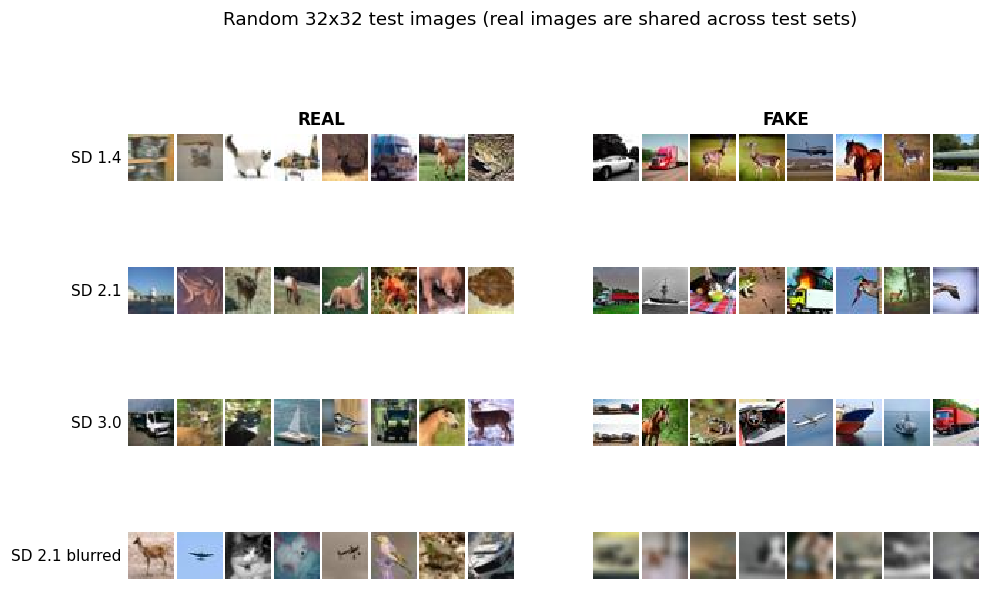

In [10]:
# One fixed colour per model across every figure
MODEL_COLORS = {"resnet50": "#2a78d6", "vit_small": "#eb6834"}
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e5e4df",
    "axes.axisbelow": True, "axes.edgecolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "lines.linewidth": 2, "legend.frameon": False,
})


def load_split(name):
    with np.load(DATA_DIR / f"{name}.npz") as z:
        return z["x"], z["y"]


test_sets = {name: load_split(name) for name in TEST_SETS}
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(len(test_sets), 2, figsize=(10, 1.5 * len(test_sets)), squeeze=False)
for r, (name, (x, y)) in enumerate(test_sets.items()):
    for c, lab in enumerate((REAL, FAKE)):
        idx = rng.choice(np.where(y == lab)[0], size=8, replace=False)
        strip = np.concatenate([np.pad(x[i], ((1, 1), (1, 1), (0, 0)), constant_values=255)
                                for i in idx], axis=1)
        ax = axes[r, c]
        ax.imshow(strip, interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for s in ax.spines.values():
            s.set_visible(False)
        if r == 0:
            ax.set_title(LABEL_NAMES[lab])
        if c == 0:
            ax.set_ylabel(TEST_SETS[name], rotation=0, ha="right", va="center")
fig.suptitle("Random 32x32 test images (real images are shared across test sets)", y=1.02)
fig.savefig(FIG_DIR / "01_sample_images.png")
plt.show()

### Frequency spectra

The average Fourier spectrum shows periodic patterns that aren't visible to the eye. Differences between the real and fake columns hint at the "fingerprints" a detector can learn. Generators are known to leave such traces (Corvi et al., 2023).

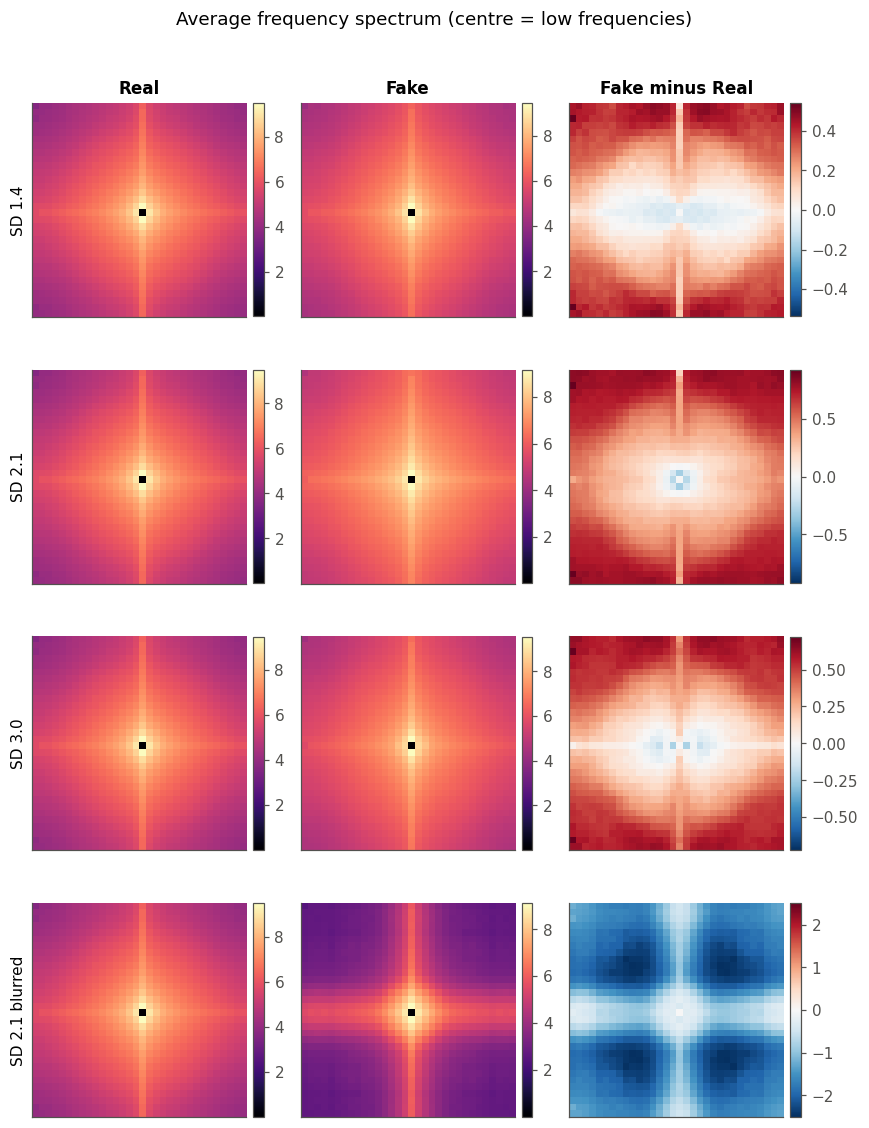

In [11]:
def mean_log_spectrum(x):
    """Average centred log-magnitude 2D Fourier spectrum of the grayscale images."""
    g = x.astype(np.float32) @ np.array([0.299, 0.587, 0.114], dtype=np.float32)
    g -= g.mean(axis=(1, 2), keepdims=True)
    return np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(g), axes=(1, 2)))).mean(axis=0)


fig, axes = plt.subplots(len(test_sets), 3, figsize=(8, 2.6 * len(test_sets)), squeeze=False)
for r, (name, (x, y)) in enumerate(test_sets.items()):
    sr, sf = mean_log_spectrum(x[y == REAL]), mean_log_spectrum(x[y == FAKE])
    lim = np.abs(sf - sr).max()
    panels = [(sr, "Real", {"cmap": "magma"}), (sf, "Fake", {"cmap": "magma"}),
              (sf - sr, "Fake minus Real", {"cmap": "RdBu_r", "norm": TwoSlopeNorm(0, -lim, lim)})]
    for c, (img, title, kw) in enumerate(panels):
        ax = axes[r, c]
        im = ax.imshow(img, **kw)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if r == 0:
            ax.set_title(title)
        if c == 0:
            ax.set_ylabel(TEST_SETS[name])
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
fig.suptitle("Average frequency spectrum (centre = low frequencies)", y=1.0)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_frequency_spectra.png")
plt.show()